# C1T5: Initial PRRIP (100k Ranking Interval)


## Libraries

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

## Final IPC Values


In [10]:
workloads = ['chirper', 'tomcat', 'omnetpp', 'mcf', 'tpcc']

ipc = pd.DataFrame({
    'LRU': [0.3, 0.369342, 0.216998, 0.323275, 0.40745],
    'SRRIP3': [0.303198, 0.368025, 0.217984, 0.321831, 0.406845],
    'PRRIP': [0.309527, 0.377175, 0.224258, 0.320214, 0.406616],
}, index=workloads)

ipc.round(6)


,LRU,SRRIP3,PRRIP
chirper,0.300000,0.303198,0.309527
tomcat,0.369342,0.368025,0.377175
omnetpp,0.216998,0.217984,0.224258
mcf,0.323275,0.321831,0.320214
tpcc,0.407450,0.406845,0.406616


## Best Fixed Priority


In [11]:
orders = ["IDP", "IPD", "DIP", "DPI", "PID", "PDI"]
fixed_rows = []

for workload in workloads:
    values = {}
    for order in orders:
        df = pd.read_csv(f"../data/{workload}_{order}_100k.csv")
        values[order] = df["instructions"].sum() / df["cycles"].sum()
    best_ipc = max(values.values())
    best_orders = []
    for order in orders:
        if values[order] == best_ipc:
            best_orders.append(order)
    fixed_rows.append({
        "workload": workload,
        "best_order": ", ".join(best_orders),
        "best_fixed_ipc": best_ipc
    })

fixed = pd.DataFrame(fixed_rows).set_index("workload")
fixed.round(6)


,best_order,best_fixed_ipc
workload,,
chirper,PID,0.308196
tomcat,PID,0.375631
omnetpp,"IPD, PID",0.223544
mcf,"IPD, PID",0.323372
tpcc,PID,0.406870


## IPC Comparison

In [12]:
comparison = ipc.copy()
comparison["Best fixed"] = fixed["best_fixed_ipc"]
comparison = comparison[["LRU", "SRRIP3", "Best fixed", "PRRIP"]]
comparison.round(6)


,LRU,SRRIP3,Best fixed,PRRIP
chirper,0.300000,0.303198,0.308196,0.309527
tomcat,0.369342,0.368025,0.375631,0.377175
omnetpp,0.216998,0.217984,0.223544,0.224258
mcf,0.323275,0.321831,0.323372,0.320214
tpcc,0.407450,0.406845,0.406870,0.406616


## PRRIP Gain and Loss


In [13]:
gains = pd.DataFrame(index=workloads)
gains["vs LRU"] = (comparison["PRRIP"] / comparison["LRU"] - 1) * 100
gains["vs SRRIP3"] = (comparison["PRRIP"] / comparison["SRRIP3"] - 1) * 100
gains["vs Best fixed"] = (comparison["PRRIP"] / comparison["Best fixed"] - 1) * 100
gains.round(3)


,vs LRU,vs SRRIP3,vs Best fixed
chirper,3.176,2.087,0.432
tomcat,2.121,2.486,0.411
omnetpp,3.346,2.878,0.319
mcf,-0.947,-0.502,-0.976
tpcc,-0.205,-0.056,-0.062


## Overall IPC

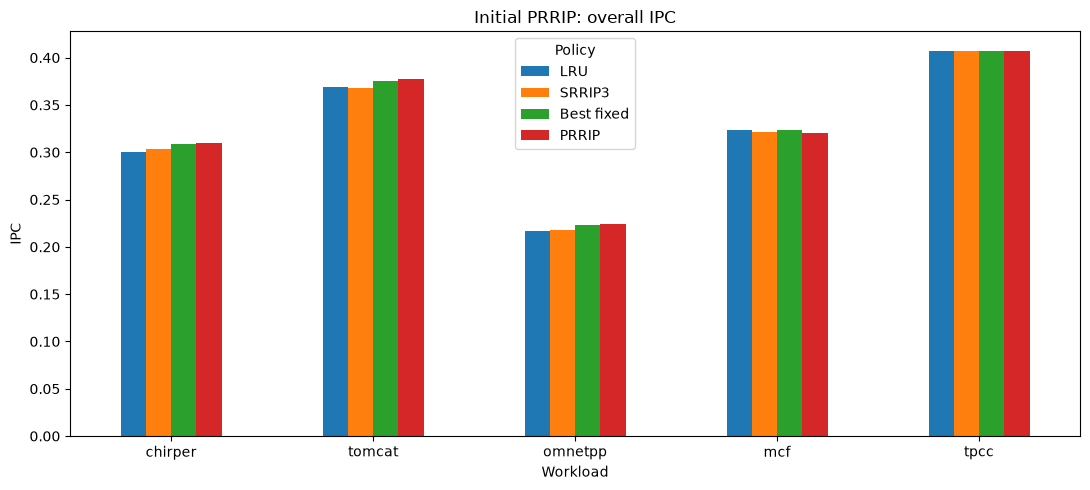

In [14]:
comparison.plot.bar(figsize=(11, 5))
plt.title("Initial PRRIP: overall IPC")
plt.xlabel("Workload")
plt.ylabel("IPC")
plt.xticks(rotation=0)
plt.legend(title="Policy")
plt.tight_layout()
plt.savefig("../results/c1t5_ipc.png", dpi=200)
plt.show()


## IPC Gain and Loss

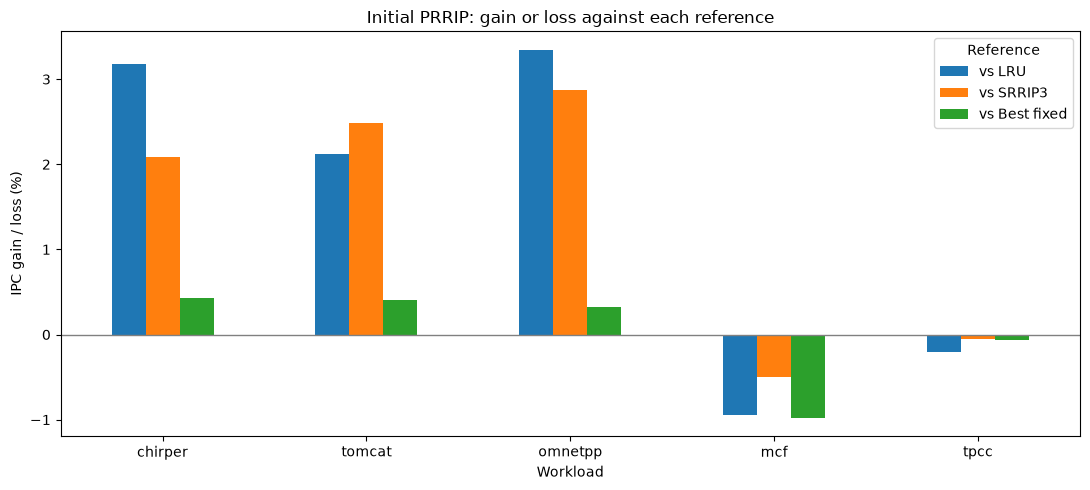

In [15]:
gains.plot.bar(figsize=(11, 5))
plt.axhline(0, color="grey", linewidth=1)
plt.title("Initial PRRIP: gain or loss against each reference")
plt.xlabel("Workload")
plt.ylabel("IPC gain / loss (%)")
plt.xticks(rotation=0)
plt.legend(title="Reference")
plt.tight_layout()
plt.savefig("../results/c1t5_ipc_gain.png", dpi=200)
plt.show()


## Findings

In [16]:
for workload in workloads:
    print(f"{workload}: PRRIP IPC = {comparison.loc[workload, 'PRRIP']:.6f}; "
          f"vs LRU = {gains.loc[workload, 'vs LRU']:+.3f}%; "
          f"vs SRRIP3 = {gains.loc[workload, 'vs SRRIP3']:+.3f}%; "
          f"vs best fixed = {gains.loc[workload, 'vs Best fixed']:+.3f}%")


chirper: PRRIP IPC = 0.309527; vs LRU = +3.176%; vs SRRIP3 = +2.087%; vs best fixed = +0.432%
tomcat: PRRIP IPC = 0.377175; vs LRU = +2.121%; vs SRRIP3 = +2.486%; vs best fixed = +0.411%
omnetpp: PRRIP IPC = 0.224258; vs LRU = +3.346%; vs SRRIP3 = +2.878%; vs best fixed = +0.319%
mcf: PRRIP IPC = 0.320214; vs LRU = -0.947%; vs SRRIP3 = -0.502%; vs best fixed = -0.976%
tpcc: PRRIP IPC = 0.406616; vs LRU = -0.205%; vs SRRIP3 = -0.056%; vs best fixed = -0.062%
